# 12 — Walk-Forward Backtesting

**Goal:** answer the question the earlier notebooks deliberately left open:
does actually *using* the ML risk-prediction signal to manage exposure
improve risk-adjusted returns, compared to an equal-weight benchmark and a
periodically-reoptimized (minimum-variance) strategy — net of transaction
costs, and using a model that's genuinely **retrained from scratch at every
rebalance date using only data available at that date** (true walk-forward,
not train-once-and-freeze)?

All three strategies below run through the same `src/backtesting/engine.py`
walk-forward loop: signals use only data through date t, trades execute at
t+1, and transaction costs are charged on every rebalance.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["figure.figsize"] = (10, 5)

np.random.seed(42)

from notebooks.nb_utils import fetch_price_panel

TICKERS = ["AAPL", "MSFT", "GLD", "BND", "SPY"]
START = "2019-01-01"

price_panel, used_synthetic = fetch_price_panel(TICKERS, START)
returns_panel = price_panel.pct_change().dropna()
print(f"Loaded {price_panel.shape[0]} rows x {price_panel.shape[1]} tickers. Synthetic data: {used_synthetic}")
price_panel.tail()

Failed to get ticker 'SPY' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


Failed to get ticker 'BND' reason: Expecting value: line 1 column 1 (char 0)


HTTP Error 403: Host not in allowlist: query2.finance.yahoo.com. Add this host to your network egress settings to allow access.


HTTP Error 403: Host not in allowlist: query1.finance.yahoo.com. Add this host to your network egress settings to allow access.


... (7 outputs left out)

['SPY', 'BND']: JSONDecodeError('Expecting value: line 1 column 1 (char 0)')


['GLD', 'MSFT', 'AAPL']: possibly delisted; no timezone found


[info] Live data unavailable (KeyError); using synthetic demo data instead.
Loaded 2004 rows x 5 tickers. Synthetic data: True


,AAPL,MSFT,GLD,BND,SPY
2026-08-31,229.681016,128.274867,119.914845,364.746718,107.728124
2026-09-01,227.093540,128.294744,120.000708,372.445526,106.711406
2026-09-02,229.155329,127.875189,121.085078,365.765614,106.991434
2026-09-03,232.958620,125.652809,122.697759,374.610608,107.656847
2026-09-04,232.705684,125.622649,120.900524,369.667262,106.661264


In [2]:
from src.backtesting.engine import (
    run_walk_forward_backtest, equal_weight_strategy, make_periodic_reoptimization_strategy,
)
from src.backtesting.risk_managed_strategy import make_risk_managed_strategy
from src.portfolio.optimization import minimum_variance_portfolio

reopt_strategy = make_periodic_reoptimization_strategy(
    minimum_variance_portfolio, lookback_days=126, max_weight=0.5,
)
# The risk-managed strategy wraps equal_weight_strategy as its BASE
# allocation, then overlays a walk-forward-retrained risk classifier that
# cuts exposure toward the lowest-volatility asset when predicted risk is
# HIGH -- see src/backtesting/risk_managed_strategy.py for the full
# mechanism and its own leakage tests.
risk_managed_strategy = make_risk_managed_strategy(
    equal_weight_strategy, defensive_scale=0.5, model_name="logistic_regression",
)

print("Running equal-weight benchmark...")
result_equal = run_walk_forward_backtest(returns_panel, equal_weight_strategy, rebalance_frequency="monthly")
print("Running periodically-reoptimized (min-variance) strategy...")
result_reopt = run_walk_forward_backtest(returns_panel, reopt_strategy, rebalance_frequency="monthly")
print("Running ML risk-managed strategy (retrains a classifier at every rebalance date)...")
result_risk_managed = run_walk_forward_backtest(returns_panel, risk_managed_strategy, rebalance_frequency="monthly")
print("Done.")

Running equal-weight benchmark...


Running periodically-reoptimized (min-variance) strategy...


Running ML risk-managed strategy (retrains a classifier at every rebalance date)...


Done.


In [3]:
comparison = pd.DataFrame({
    "equal_weight": result_equal.performance,
    "reoptimized_min_var": result_reopt.performance,
    "ml_risk_managed": result_risk_managed.performance,
}).T
comparison[["annualized_return", "annualized_volatility", "sharpe_ratio", "max_drawdown", "total_transaction_costs", "num_rebalances"]].round(4)

,annualized_return,annualized_volatility,sharpe_ratio,max_drawdown,total_transaction_costs,num_rebalances
equal_weight,0.0949,0.1142,0.6562,-0.1703,0.0010,93.0
reoptimized_min_var,0.0730,0.0920,0.5762,-0.1814,0.0127,93.0
ml_risk_managed,0.0894,0.1098,0.6326,-0.1703,0.0079,93.0


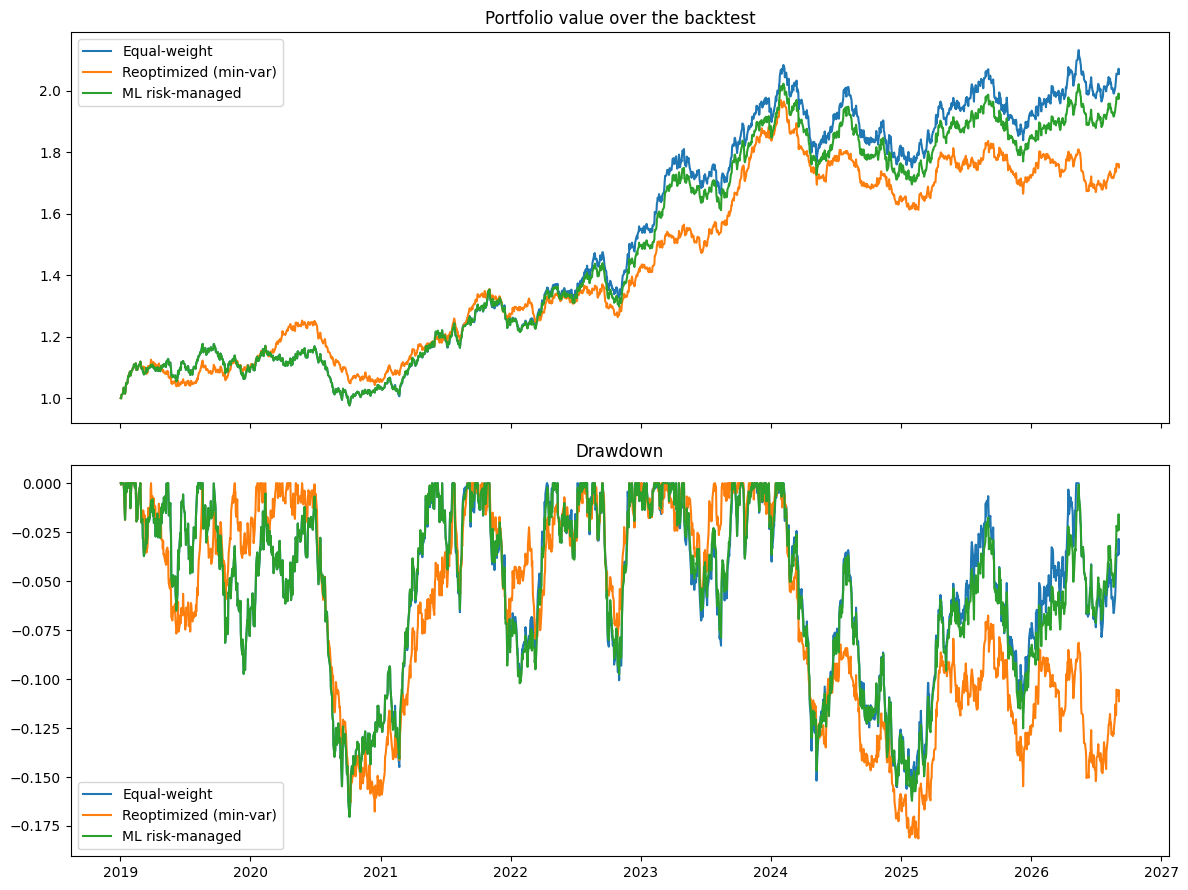

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for result, label in [(result_equal, "Equal-weight"), (result_reopt, "Reoptimized (min-var)"), (result_risk_managed, "ML risk-managed")]:
    axes[0].plot(result.portfolio_value, label=label)
axes[0].legend()
axes[0].set_title("Portfolio value over the backtest")

for result, label in [(result_equal, "Equal-weight"), (result_reopt, "Reoptimized (min-var)"), (result_risk_managed, "ML risk-managed")]:
    wealth = result.portfolio_value / result.portfolio_value.iloc[0]
    dd = wealth / wealth.cummax() - 1
    axes[1].plot(dd, label=label)
axes[1].legend()
axes[1].set_title("Drawdown")
plt.tight_layout()
plt.show()

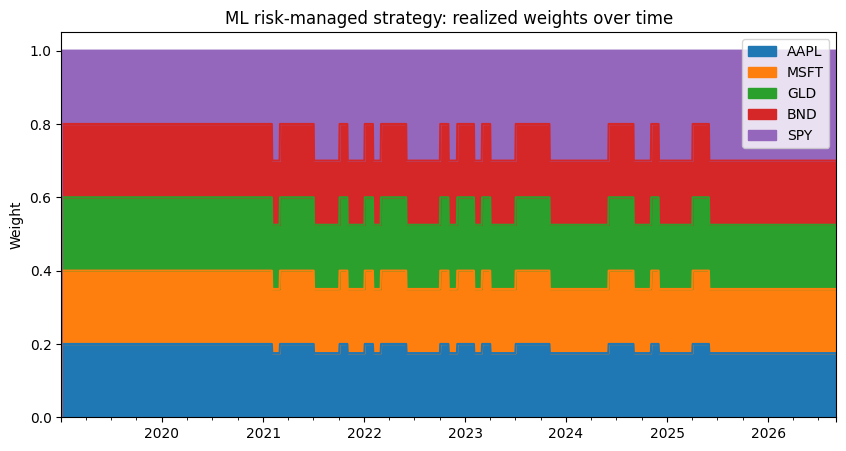

In [5]:
result_risk_managed.weights_history.plot.area(title="ML risk-managed strategy: realized weights over time")
plt.ylabel("Weight")
plt.show()

## Did the ML risk overlay actually help?

Compare max drawdown and Sharpe ratio specifically -- the overlay is *designed* to trade some upside for a shallower worst-case drawdown by de-risking when the classifier predicts elevated loss probability. The honest test is whether that trade was worth it on this data, not whether the overlay exists.

In [6]:
verdict_rows = []
for name, result in [("equal_weight", result_equal), ("reoptimized_min_var", result_reopt), ("ml_risk_managed", result_risk_managed)]:
    verdict_rows.append({
        "strategy": name,
        "sharpe_ratio": result.performance["sharpe_ratio"],
        "max_drawdown": result.performance["max_drawdown"],
        "annualized_return": result.performance["annualized_return"],
    })
verdict = pd.DataFrame(verdict_rows).set_index("strategy")
print(verdict.round(4))

best_sharpe = verdict["sharpe_ratio"].idxmax()
shallowest_drawdown = verdict["max_drawdown"].idxmax()  # max_drawdown is negative; idxmax = least negative = shallowest
print(f"\nBest Sharpe ratio: {best_sharpe}")
print(f"Shallowest max drawdown: {shallowest_drawdown}")

if shallowest_drawdown == "ml_risk_managed":
    print("\nOn this run, the ML risk overlay DID reduce the worst drawdown relative to the other two strategies.")
else:
    print(f"\nOn this run, the ML risk overlay did NOT produce the shallowest drawdown -- '{shallowest_drawdown}' did.")
print("This is an honest, run-specific empirical result on this dataset -- not a general claim that risk overlays "
      "work or don't work. See the discussion below for why a single run's verdict should not be over-interpreted.")

                     sharpe_ratio  max_drawdown  annualized_return
strategy                                                          
equal_weight               0.6562       -0.1703             0.0949
reoptimized_min_var        0.5762       -0.1814             0.0730
ml_risk_managed            0.6326       -0.1703             0.0894

Best Sharpe ratio: equal_weight
Shallowest max drawdown: equal_weight

On this run, the ML risk overlay did NOT produce the shallowest drawdown -- 'equal_weight' did.
This is an honest, run-specific empirical result on this dataset -- not a general claim that risk overlays work or don't work. See the discussion below for why a single run's verdict should not be over-interpreted.


## Honest discussion

This is now a genuine, if small-sample, empirical comparison — not two disconnected pipeline halves. A few things to keep in mind when reading the verdict above:

- **Retraining cost**: the ML risk-managed strategy retrains a full classifier (with feature selection) at every single monthly rebalance, using only data available at that point — this is exactly the same computational cost a live deployment would face, not a shortcut.
- **Small-sample caveat applies here too**: exactly like notebooks 11 and 13, a single backtest run on one asset universe and one history (possibly synthetic — see the `used_synthetic` flag in the setup cell) is one draw from a highly variable process. The verdict above should not be treated as proof the approach generalizes; it demonstrates that the *pipeline* for testing this question is now real and reproducible, which is the actual deliverable of this notebook.
- **The defensive rule is deliberately simple** (cut exposure by a fixed fraction, move the rest to the lowest-vol asset) rather than a second optimization layered on top of the first — this keeps the overlay's behavior explainable, at the cost of leaving potential improvement (e.g. a smoother, probability-scaled exposure cut) on the table.
- Every rebalance in every strategy above is decided using only trailing data, then executed the next trading day — the leakage tests in `tests/test_backtesting.py` and `tests/test_risk_managed_strategy.py` confirm perturbing future returns never changes earlier portfolio values, including for the retraining strategy.
- Transaction costs are visibly subtracted at every rebalance for all three strategies; a strategy that looks good gross of costs can look materially worse net of them.

Continue to **13 — Model Evaluation and Results**.